In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import zipfile

zip_path = '/content/drive/MyDrive/prml-2026-course-assignment-4.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

Loading and preprocessing data...


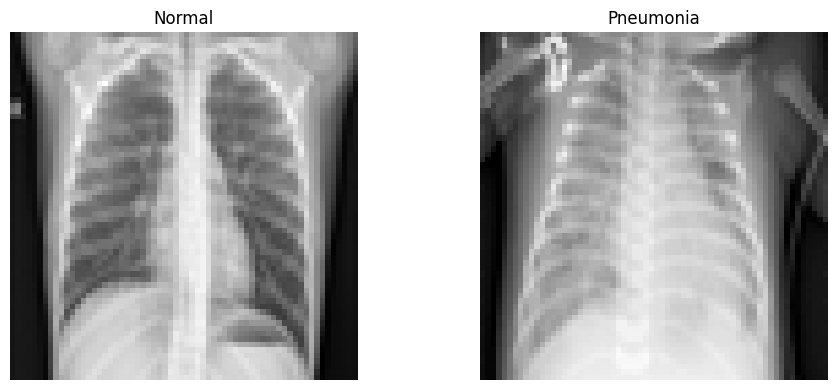

Training Matrix Shape: (4684, 4096) | Labels: (4684,)
Validation Matrix Shape: (585, 4096) | Labels: (585,)
Starting optimization loop...
Epoch 1/1000 - Train Loss: 0.7533 | Val Loss: 0.7509
Epoch 100/1000 - Train Loss: 0.3428 | Val Loss: 0.3429
Epoch 200/1000 - Train Loss: 0.2823 | Val Loss: 0.2829
Epoch 300/1000 - Train Loss: 0.2527 | Val Loss: 0.2546
Epoch 400/1000 - Train Loss: 0.2344 | Val Loss: 0.2376
Epoch 500/1000 - Train Loss: 0.2216 | Val Loss: 0.2262
Epoch 600/1000 - Train Loss: 0.2121 | Val Loss: 0.2179
Epoch 700/1000 - Train Loss: 0.2047 | Val Loss: 0.2116
Epoch 800/1000 - Train Loss: 0.1987 | Val Loss: 0.2066
Epoch 900/1000 - Train Loss: 0.1938 | Val Loss: 0.2026
Epoch 1000/1000 - Train Loss: 0.1897 | Val Loss: 0.1992

Model Performance Summary:
Metric       | Value   
-----------------------
Accuracy     | 93.2%
Precision    | 93.7%
Recall       | 97.2%
F1_score     | 95.4%


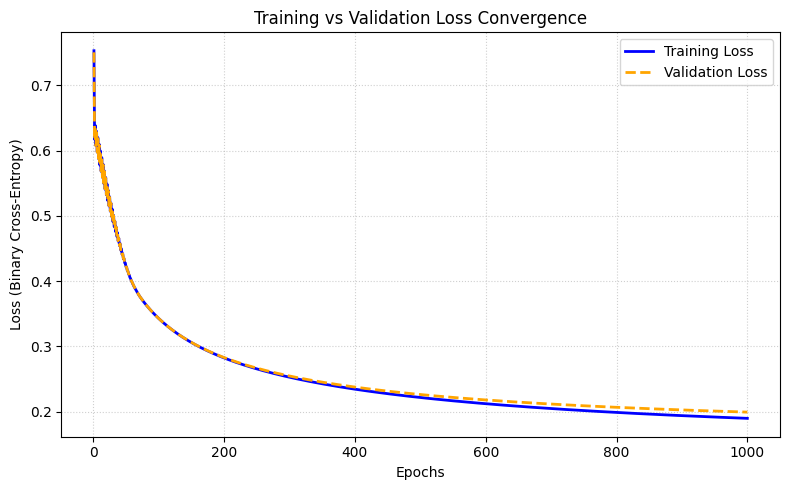

w_grid_new: [[ 0.00661149 -0.00127263  0.00057074 ...  0.01008123  0.01910429
   0.01831108]
 [ 0.02183822  0.01769819  0.01823059 ...  0.01363792  0.02709901
   0.02883205]
 [ 0.02510581  0.01912345  0.01491755 ...  0.01449326  0.02860927
   0.02916675]
 ...
 [ 0.02609904  0.02624918  0.03048692 ...  0.01035114  0.02497234
   0.02882956]
 [ 0.02512396  0.02568765  0.03169622 ...  0.01635912  0.02892413
   0.03500267]
 [ 0.03435156  0.03141214  0.03653354 ...  0.00237455  0.01348229
   0.01984124]]


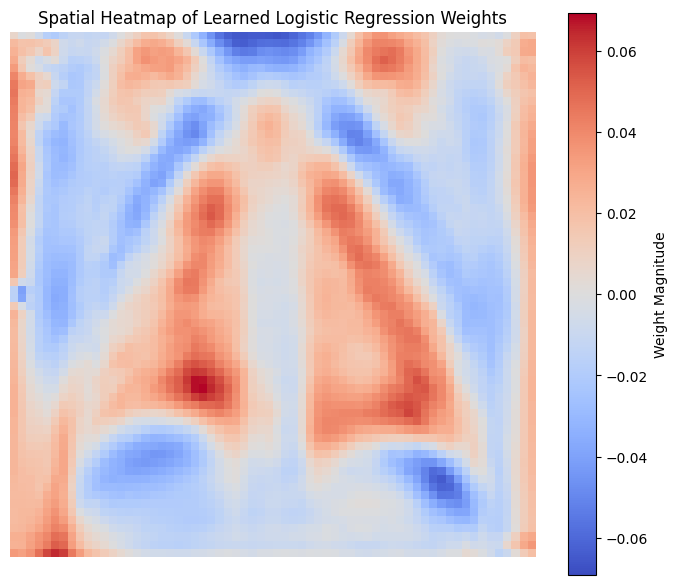

In [16]:

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def preprocess_and_flatten(image_dir, target_size=(64, 64)):
    """
    Loads images from 'Normal' and 'Pneumonia' subdirectories, resizes them,
    normalizes pixel values, flattens them, and compiles the data matrix.

    Args:
        image_dir (str): Path to the dataset split directory (train or val).
        target_size (tuple): Destination resolution (height, width).
    Returns:
        X (np.ndarray): Data matrix of shape (N, D) where D = target_size[0] * target_size[1].
        y (np.ndarray): Binary labels vector of shape (N,) where 0=Normal, 1=Pneumonia.
    """
    X_list = []
    y_list = []

    # Define class mappings
    class_mapping = {'NORMAL': 0, 'PNEUMONIA': 1}

    for class_name, label in class_mapping.items():
        dir_path = os.path.join(image_dir, class_name)
        if not os.path.exists(dir_path):
            continue

        for img_name in sorted(os.listdir(dir_path)):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(dir_path, img_name)

                img=Image.open(img_path).convert('L')

                img_scaled=img.resize(target_size,Image.LANCZOS)
                img_normalized=np.array(img_scaled, dtype=np.float32)/255.0

                img_flattened=img_normalized.reshape(-1)

                X_list.append(img_flattened)
                y_list.append(label)


    X = np.array(X_list)
    y = np.array(y_list)
    return X, y


def sigmoid(z):
    return 1.0/(1.0+np.exp(-z))

"""
    Computes the element-wise logistic sigmoid function.
    """

    # ----------------------------------------------------------------------
    # TODO: TASK 2a
    # Compute and return the sigmoid function. Take care to prevent
    # potential numerical overflow/underflow if necessary.
    # ----------------------------------------------------------------------

    # pass

def compute_loss(X, y, w, b):

    N = X.shape[0]
    eps=np.exp(-15)
    P = sigmoid(X@w+b)
    P= np.clip(P,eps,1.0-eps)
    return (-1/N)*(np.dot(y,np.log(P))+np.dot(1-y,np.log(1-P)))

"""
    Computes the average Binary Cross-Entropy (Negative Log-Likelihood) loss.
    """
    # ----------------------------------------------------------------------
    # TODO: TASK 2c
    # Compute the average BCE loss over all N samples.
    # Add a tiny epsilon (e.g., 1e-15) inside logs to prevent log(0).
    # ----------------------------------------------------------------------

def compute_gradients(X, y, w, b):
    """
    Computes analytical gradients of the loss function with respect to w and b.
    """
    N = X.shape[0]
    P = sigmoid(X@w+b)

    # ----------------------------------------------------------------------
    # TODO: TASK 2d
    # Compute and return the analytical gradients dw (shape: D,) and db (scalar).
    # ----------------------------------------------------------------------
    dw = (1/N)*(X.T @(P-y))
    db = (1/N)*np.sum(P-y)
    return dw, db

def compute_evaluation_metrics(y_true, y_pred_probs, threshold=0.5):
    N=len(y_true)
    metrics = {
        'accuracy': 0.0,
        'precision': 0.0,
        'recall': 0.0,
        'f1_score': 0.0
    }

    y_pred_probs=(y_pred_probs >= threshold).astype(int)

    true_positive=np.sum((y_true==1)&(y_pred_probs==1))
    false_positive=np.sum((y_true==0)&(y_pred_probs==1))
    true_negative=np.sum((y_true==0)&(y_pred_probs==0))
    false_negative=np.sum((y_true==1)&(y_pred_probs==0))

    accuracy= (true_positive+true_negative)/ N
    precision= true_positive/(true_positive+false_positive) if(true_positive+false_positive)>0 else 0.0
    recall = true_positive/(true_positive+false_negative) if(true_positive+false_negative)>0 else 0.0
    f1_score= 2*(precision*recall)/(precision+recall) if (precision+recall)>0 else 0.0

    return {
        'accuracy':accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1_score
    }

def train_model(X_train, y_train, X_val, y_val, epochs=1000, learning_rate=0.01):
    """
    Executes the full Gradient Descent optimization loop and logs performance.
    """
    N, D = X_train.shape

    w = np.zeros(D)
    b = 0.0

    train_losses = []
    val_losses = []

    print("Starting optimization loop...")
    for epoch in range(1, epochs + 1):
        dw,db= compute_gradients(X_train, y_train, w, b)
        w=w-learning_rate*dw
        b=b-learning_rate*db


        train_losses.append(compute_loss(X_train, y_train, w, b))
        val_losses.append(compute_loss(X_val, y_val, w, b))

        if epoch % 100 == 0 or epoch == 1:
            train_loss = compute_loss(X_train, y_train, w, b)
            val_loss = compute_loss(X_val, y_val, w, b)
            print(f"Epoch {epoch}/{epochs} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    return w, b, train_losses, val_losses

if __name__ == "__main__":
    # Define relative paths to your local dataset folders downloaded from Kaggle
    TRAIN_DIR = "/content/dataset/student_pack/student_pack/train"
    VAL_DIR = "/content/dataset/student_pack/student_pack/val"

    print("Loading and preprocessing data...")
    X_train, y_train = preprocess_and_flatten(TRAIN_DIR)
    X_val, y_val = preprocess_and_flatten(VAL_DIR)

    plt.figure(figsize=(10, 4))
    normal_index = np.where(y_train == 0)[0][0]
    pneumonia_index = np.where(y_train == 1)[0][0]

    plt.subplot(1, 2, 1)
    plt.imshow(X_train[normal_index].reshape(64, 64), cmap='gray')
    plt.title("Normal")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(X_train[pneumonia_index].reshape(64, 64), cmap='gray')
    plt.title("Pneumonia")
    plt.axis('off')
    plt.tight_layout()
    plt.show()


    print(f"Training Matrix Shape: {X_train.shape} | Labels: {y_train.shape}")
    print(f"Validation Matrix Shape: {X_val.shape} | Labels: {y_val.shape}")

    # Train the model with frozen assignment hyperparameters
    EPOCHS = 1000
    LR = 0.01
    w, b, train_losses, val_losses = train_model(X_train, y_train, X_val, y_val, epochs=EPOCHS, learning_rate=LR)

    y_val_pred_probs = sigmoid(X_val @ w + b)
    val_metrics = compute_evaluation_metrics(y_val, y_val_pred_probs)

    print("\nModel Performance Summary:")
    print(f"{'Metric':<12} | {'Value':<8}")
    print("-" * 23)
    for metric, val in val_metrics.items():
        print(f"{metric.capitalize():<12} | {val * 100:.1f}%")

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, label='Training Loss', color='blue', linewidth=2)
plt.plot(range(1, EPOCHS + 1), val_losses, label='Validation Loss', color='orange', linestyle='--', linewidth=2)

plt.xlabel('Epochs')
plt.ylabel('Loss (Binary Cross-Entropy)')
plt.title('Training vs Validation Loss Convergence')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

w_grid = w.reshape((64, 64))
print('w_grid_new:',w_grid)

plt.figure(figsize=(7, 6))

max_abs = np.max(np.abs(w_grid))
im = plt.imshow(w_grid, cmap='coolwarm', vmin=-max_abs, vmax=max_abs)

plt.colorbar(im, label='Weight Magnitude')
plt.title('Spatial Heatmap of Learned Logistic Regression Weights')
plt.axis('off')
plt.tight_layout()
plt.show()


# Importance of Recall
In medical diagnostics—specifically in screening for conditions like pneumonia—Recall (Sensitivity) measures the proportion of actual positive cases that the model correctly identifies.

Consequence of False Negatives: A False Negative (FN) occurs when a patient with pneumonia is predicted by the model as "Normal" and sent home without treatment. Missed pneumonia diagnoses can lead to severe complications, rapid disease progression, or life-threatening outcomes.

Consequence of False Positives: A False Positive (FP) occurs when a healthy patient is predicted to have pneumonia. The cost here involves temporary anxiety, a follow-up consultation, or additional confirmatory imaging.

Asymmetric Risk: The clinical harm of an untreated case (False Negative) drastically outweighs the inconvenience of additional diagnostic follow-ups (False Positive). Maximizing Recall minimizes False Negatives, ensuring that as few sick patients as possible fall through the cracks.

# Inference from heatmap
Red regions from the heat map indicate the most effect is observed from the differences in the regions with most red regions which are along the lower lung fields and central chest region as well as distinct focal regions corresponding to lung parenchyma. Higher pixel intensity indicates stronger prediction of pneumonia compared to the lighter red pixel

Blue regions associated with negative weights represents the normal-air filled tissue, indicating these regions lower the prediction of pneumonia and the darker the intensity, the more is the effect
